# Flipkart Mobile Market Analysis using Web Scraping

## Objective

The objective of this project is to collect product data from Flipkart using Python web scraping techniques and transform the extracted data into a structured dataset for analysis. The project aims to clean and organize the data, perform exploratory data analysis (EDA), create visualizations, and generate business insights related to product pricing, ratings, discounts, and customer preferences.

## Import Libraries

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

## Test the website

In [2]:
url = "https://www.flipkart.com/"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/137.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,/;q=0.8",
    "Referer": "https://www.google.com/"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


## Scrape the Data

In [6]:
soup = BeautifulSoup(response.text, "html.parser")

In [7]:
soup

<!DOCTYPE html>
 <html class="useInterFont" lang="en-IN"> <head><link href="https://1.rome.api.flipkart.com" rel="dns-prefetch"/><link href="https://2.rome.api.flipkart.com" rel="dns-prefetch"/><link crossorigin="" href="https://static-assets-web.flixcart.com" rel="preconnect"/> <link href="https://rukminim2.flixcart.com" rel="preconnect"/><link href="https://static-assets-web.flixcart.com/batman-returns/batman-returns/p/images/logo_lite-cbb357.png" rel="icon" type="image/png"/><meta charset="utf-8"/><meta content="width=device-width,minimum-scale=1,user-scalable=no" name="viewport"/><link href="https://static-assets-web.flixcart.com/apex-static/images/fk-lite-assets/app-icons/app-icon_192x192.png" rel="apple-touch-icon"/><link href="https://static-assets-web.flixcart.com/apex-static/images/fk-lite-assets/app-icons/app-icon_192x192.png" rel="apple-touch-icon" sizes="192x192"/><link href="https://static-assets-web.flixcart.com/apex-static/images/fk-lite-assets/app-icons/app-icon_256x256

In [8]:
url="https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&as=on&as-show=on&otracker=AS_QueryStore_OrganicAutoSuggest_1_4_na_na_na&otracker1=AS_QueryStore_OrganicAutoSuggest_1_4_na_na_na&as-pos=1&as-type=RECENT&suggestionId=mobile+5g%7CMobiles&requestId=9b09a22c-60fb-4302-a14a-a138176d4308&as-searchtext=mobile%205g"
page=requests.get(url,headers = headers)
print(page)
soup=BeautifulSoup(page.text)
b=soup.find_all("div",class_="RG5Slk")
brand=[]
for i in b:
    a=i.text
    if a :
        brand.append(a.split()[0])
    else :
        brand.append(np.nan)
m=soup.find_all("div",class_="RG5Slk")
model=[]
for i in m:
    a=i.text
    if "(" in a :
        model.append(a.split("(")[0])
    else :
        model.append(np.nan)
c=soup.find_all("div",class_="RG5Slk")       
color=[]
for i in c:
    a=i.text
    if "(" in a :
        color.append(a.split("(")[1].split(",")[0])
    else :
        color.append(np.nan)
p=soup.find_all("div",class_="hZ3P6w DeU9vF")
price=[]
for i in p:
    a=i.text
    regex=re.sub(r"[₹,]","",a)
    if regex:
        price.append(regex)
    else :
        price.append(np.nan)
features=soup.find_all("div",class_="CMXw7N")
RAM=[]
for i in features :
    a=i.text
    regex=re.findall(r"(\d+)\sGB\sRAM",a)
    if regex:
        RAM.append(regex[0])
    else :
        RAM.append(np.nan)
ROM=[]
for i in features :
    a=i.text
    regex=re.findall(r"(\d+)\sGB\sROM",a)
    if regex:
        ROM.append(regex[0])
    else :
        ROM.append(np.nan)
display=[]
for i in features :
    a=i.text
    regex=re.findall(r"(\d+\.\d+)\scm",a)
    if regex:
        display.append(regex[0])
    else :
        display.append(np.nan)
battery=[]
for i in features :
    a=i.text
    regex=re.findall(r"(\d+)\smAh",a)
    if regex:
        battery.append(regex[0])
    else :
        battery.append(np.nan)

<Response [200]>


In [9]:
data = {
    "Brand": brand,
    "Model": model,
    "RAM": RAM,
    "ROM": ROM,
    "Battery": battery,
    "Price": price,
    "Display": display,
    "Color": color
}


In [10]:
df = pd.DataFrame(data)

In [11]:
df

,Brand,Model,RAM,ROM,Battery,Price,Display,Color
0,BOLTT,BOLTT ACE 5G,4,64,6000,11999,17.25,Sky Blue
1,OPPO,OPPO K14 Plus 5G,6,128,8000,32999,17.22,Star White
2,LAVA,LAVA Virat V1 5G,4,64,6000,13499,17.14,Arya Blue
3,HMD,HMD Vibe2 Pro 5G,6,128,6000,16999,17.22,Cosmic Purple
4,realme,realme P4 Lite 5G,4,64,7000,16249,17.27,Mosaic Green
5,realme,realme P4 Power 5G Charger in the Box,8,128,10001,29999,17.27,TransSilver
6,vivo,vivo T5x 5G,6,128,7200,27249,17.17,Cosmic Green
7,Mivi,Mivi One 5G,4,128,6000,13999,17.14,Blue
8,Apple,Apple iPhone 17,NaN,256,NaN,88999,16.0,White
9,Samsung,Samsung Galaxy A36 5G,8,256,5000,29999,17.02,Dark Blue


In [21]:
brand=[]
model=[]
color=[]
price=[]
RAM=[]
ROM=[]
display=[]
battery=[]
for i in range(1,31):
    url=f"https://www.flipkart.com/search?q=
    mobiles&otracker=search&otracker1=search
    &marketplace=FLIPKART&as-show=on&as=off&page={i}"
    page=requests.get(url,headers=headers)
    print(page)
    time.sleep(2)
    soup=BeautifulSoup(page.text)
    b=soup.find_all("div",class_="RG5Slk")
    
    for i in b:
        a=i.text
        if a :
            brand.append(a.split()[0])
        else :
            brand.append(np.nan)
    m=soup.find_all("div",class_="RG5Slk")

    for i in m:
        a=i.text
        if "(" in a :
            model.append(a.split("(")[0])
        else :
            model.append(np.nan)
    c=soup.find_all("div",class_="RG5Slk")       
    
    for i in c:
        a=i.text
        if "(" in a :
            color.append(a.split("(")[1].split(",")[0])
        else :
            color.append(np.nan)
    p=soup.find_all("div",class_="hZ3P6w DeU9vF")
    
    for i in p:
        a=i.text
        regex=re.sub(r"[₹,]","",a)
        if regex:
            price.append(regex)
        else :
            price.append(np.nan)
    features=soup.find_all("div",class_="CMXw7N")
    
    for i in features :
        a=i.text
        regex=re.findall(r"(\d+)\sGB\sRAM",a)
        if regex:
            RAM.append(regex[0])
        else :
            RAM.append(np.nan)
    
    for i in features :
        a=i.text
        regex=re.findall(r"(\d+)\sGB\sROM",a)
        if regex:
            ROM.append(regex[0])
        else :
            ROM.append(np.nan)
    
    for i in features :
        a=i.text
        regex=re.findall(r"(\d+\.\d+)\scm",a)
        if regex:
            display.append(regex[0])
        else :
            display.append(np.nan)
    
    for i in features :
        a=i.text
        regex=re.findall(r"(\d+)\smAh",a)
        if regex:
            battery.append(regex[0])
        else :
            battery.append(np.nan)

<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>
<Response [200]>


In [22]:
for i in range(1,31):
    print(f"https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page={i}")

https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=1
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=2
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=3
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=4
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=5
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=6
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=7
https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page=8
https://www.flipkart.com/search?

In [23]:
data = {
    "Brand": brand,
    "Model": model,
    "RAM": RAM,
    "ROM": ROM,
    "Battery": battery,
    "Price": price,
    "Display": display,
    "Color": color
}

## Convert to Dataframe

In [24]:
df = pd.DataFrame(data)
df

,Brand,Model,RAM,ROM,Battery,Price,Display,Color
0,BOLTT,BOLTT ACE 5G,4,64,6000,11999,17.25,Sky Blue
1,BOLTT,BOLTT EVO,4,64,6000,10999,17.25,Midnight Black
2,Apple,Apple iPhone 17,NaN,256,NaN,88999,16.0,Lavender
3,LAVA,LAVA Virat V1 5G,4,64,6000,13499,17.14,Arya Blue
4,OPPO,OPPO K14 Plus 5G,6,128,8000,32999,17.22,Star White
...,...,...,...,...,...,...,...,...
715,MOTOROLA,MOTOROLA Edge 70 Max,12,256,7100,59999,17.27,PANTONE Dark Shadow
716,Google,Google Pixel 11 Pro XL,12,256,5115,134999,17.27,Fog
717,Apple,Apple iPhone 17,NaN,512,NaN,113999,16.0,Sage
718,Apple,Apple iPhone 17 Pro Max,NaN,256,NaN,149900,17.53,Cosmic Orange


## Check the dataset

In [25]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])
print("----------------------------------------------------------------------")
df.info()

Rows: 720
Columns: 8
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Brand    720 non-null    object
 1   Model    718 non-null    object
 2   RAM      695 non-null    object
 3   ROM      716 non-null    object
 4   Battery  697 non-null    object
 5   Price    720 non-null    object
 6   Display  720 non-null    object
 7   Color    718 non-null    object
dtypes: object(8)
memory usage: 45.1+ KB


## Save the scraped dataset

In [26]:
df.to_csv("Scraped_flipkart_dataset.csv", index = False)

print("Scraped Dataset Saved Successfully")

Scraped Dataset Saved Successfully


In [27]:
import os

print(os.path.exists("Scraped_flipkart_dataset.csv"))

True


## Data Cleaning

In [4]:
df = pd.read_csv("Scraped_flipkart_dataset.csv")

In [5]:
cleaned_df = df.copy()

print("Cleaning started...")

Cleaning started...


###  Check missing values

In [6]:
cleaned_df.isnull().sum()

Brand       0
Model       2
RAM        25
ROM         4
Battery    23
Price       0
Display     0
Color       2
dtype: int64

In [7]:
# duplicate rows

cleaned_df.duplicated().sum()

np.int64(276)

In [8]:
# remove duplicates

cleaned_df.drop_duplicates(inplace=True)


In [9]:
cleaned_df.dtypes

Brand       object
Model       object
RAM        float64
ROM        float64
Battery    float64
Price        int64
Display    float64
Color       object
dtype: object

In [10]:
cleaned_df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
cleaned_df["RAM"] = pd.to_numeric(df["RAM"], errors="coerce")
cleaned_df["ROM"] = pd.to_numeric(df["ROM"], errors="coerce")
cleaned_df["Display"] = pd.to_numeric(df["Display"], errors="coerce")
cleaned_df["Battery"] = pd.to_numeric(df["Battery"], errors="coerce")

In [11]:
cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 444 entries, 0 to 719
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Brand    444 non-null    object 
 1   Model    442 non-null    object 
 2   RAM      420 non-null    float64
 3   ROM      440 non-null    float64
 4   Battery  422 non-null    float64
 5   Price    444 non-null    int64  
 6   Display  444 non-null    float64
 7   Color    442 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 31.2+ KB


### Handle Missing Values

In [12]:
cleaned_df["Model"] = cleaned_df["Model"].fillna("Unknown")

In [13]:
cleaned_df["Color"] = cleaned_df["Color"].fillna("Unknown")

In [14]:
cleaned_df["RAM"] = cleaned_df["RAM"].fillna(cleaned_df["RAM"].median())

In [15]:
cleaned_df["ROM"] = cleaned_df["ROM"].fillna(cleaned_df["ROM"].median())

In [16]:
cleaned_df["Battery"] = cleaned_df["Battery"].fillna(cleaned_df["Battery"].median())

In [17]:
cleaned_df.isnull().sum()

Brand      0
Model      0
RAM        0
ROM        0
Battery    0
Price      0
Display    0
Color      0
dtype: int64

In [18]:
cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 444 entries, 0 to 719
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Brand    444 non-null    object 
 1   Model    444 non-null    object 
 2   RAM      444 non-null    float64
 3   ROM      444 non-null    float64
 4   Battery  444 non-null    float64
 5   Price    444 non-null    int64  
 6   Display  444 non-null    float64
 7   Color    444 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 31.2+ KB


## Basics of EDA (Exploratory Data Analysis) 

In [20]:
cleaned_df.describe()

,RAM,ROM,Battery,Price,Display
count,444.000000,444.000000,444.000000,444.000000,444.000000
mean,7.459459,190.990991,6241.218468,42598.761261,17.264032
std,2.826938,118.193742,1136.251522,36242.775261,2.941773
min,3.000000,0.000000,800.000000,999.000000,4.500000
25%,6.000000,128.000000,5520.000000,18999.000000,17.000000
50%,8.000000,128.000000,6000.000000,27999.000000,17.140000
75%,8.000000,256.000000,7000.000000,50249.000000,17.270000
max,16.000000,512.000000,10001.000000,179900.000000,43.740000


In [21]:
cleaned_df.describe(include="object")

,Brand,Model,Color
count,444,444,444
unique,21,157,224
top,Samsung,Nothing Phone,Black
freq,81,9,31


In [23]:
# Brand Distribution

cleaned_df["Brand"].value_counts()

Brand
Samsung     81
vivo        45
realme      42
Ai+         38
MOTOROLA    35
OPPO        29
POCO        29
REDMI       28
Apple       22
OnePlus     21
Infinix     17
Google      16
BOLTT        9
Nothing      9
HMD          8
Mivi         6
LAVA         5
itel         1
Vivo         1
Nokia        1
Tecno        1
Name: count, dtype: int64

In [24]:
# Color Distribution

cleaned_df["Color"].value_counts()

Color
Black               31
Blue                14
Green               12
Sky Blue             7
Midnight Black       7
                    ..
Passion Red 2026     1
Shadow Blue          1
Vibe Violet          1
Awesome Olive        1
Sage                 1
Name: count, Length: 224, dtype: int64

In [31]:
# Top 10 Most Expensive Mobiles

cleaned_df.nlargest(10, "Price")

,Brand,Model,RAM,ROM,Battery,Price,Display,Color
655,Apple,Apple iPhone 18 Pro max,8.0,256.0,6000.0,179900,17.53,Silver
673,Apple,Apple iPhone 18 Pro max,8.0,256.0,6000.0,179900,17.53,Black
632,Apple,Apple iPhone 17 Pro,8.0,128.0,6000.0,174900,16.00,Silver
698,Apple,Apple iPhone 17 Pro Max,8.0,512.0,6000.0,169900,17.53,Cosmic Orange
224,Apple,Apple iPhone 18 Pro,8.0,256.0,6000.0,164900,16.00,Burgundy
493,Apple,Apple iPhone 18 Pro,8.0,256.0,6000.0,164900,16.00,Glacier
462,MOTOROLA,MOTOROLA Razr fold,16.0,512.0,6000.0,159999,16.66,PANTONE Blackened blue
475,Samsung,Samsung Galaxy S26 Ultra 5G,12.0,512.0,5000.0,159999,17.53,Sky Blue
525,Samsung,Samsung Galaxy S26 Ultra 5G,12.0,512.0,5000.0,159999,17.53,White
621,Apple,Apple iPhone 17 Pro,8.0,512.0,6000.0,154900,16.00,Deep Blue


In [32]:
# Cheapest 10 Mobiles

cleaned_df.nsmallest(10, "Price")

,Brand,Model,RAM,ROM,Battery,Price,Display,Color
572,Nokia,Unknown,8.0,128.0,800.0,999,4.50,Unknown
643,itel,Unknown,8.0,128.0,1900.0,1495,7.11,Unknown
13,Ai+,Ai+ Pulse 2 FE,4.0,64.0,5000.0,9999,16.94,Blue
188,Ai+,Ai+ Pulse 2 FE,4.0,64.0,5000.0,9999,16.94,Green
535,Ai+,Ai+ Pulse 2 FE,4.0,64.0,5000.0,9999,16.94,Purple
671,LAVA,LAVA Virat V1,4.0,64.0,5000.0,10499,17.14,Deccan Grey
1,BOLTT,BOLTT EVO,4.0,64.0,6000.0,10999,17.25,Midnight Black
21,Ai+,Ai+ Pulse 2,4.0,64.0,6000.0,10999,17.13,Pink
24,Ai+,Ai+ Pulse 2,4.0,64.0,6000.0,10999,17.13,Blue
39,Ai+,Ai+ Pulse 2,4.0,64.0,6000.0,10999,17.13,Green


In [33]:
# Average Price by Brand

cleaned_df.groupby("Brand")["Price"].mean().sort_values(ascending=False)

Brand
Apple       134072.363636
Google      105499.000000
vivo         50222.333333
Samsung      48554.382716
OPPO         46067.965517
Nothing      44221.222222
MOTOROLA     40249.000000
OnePlus      38247.714286
realme       27635.142857
POCO         26430.034483
REDMI        26301.035714
Infinix      24234.294118
Tecno        19999.000000
LAVA         17099.000000
Vivo         16999.000000
Mivi         15915.666667
Ai+          15683.210526
HMD          15624.000000
BOLTT        13387.888889
itel          1495.000000
Nokia          999.000000
Name: Price, dtype: float64

In [34]:
# Average RAM by Brand

cleaned_df.groupby("Brand")["RAM"].mean()

Brand
Ai+          5.473684
Apple        8.000000
BOLTT        5.555556
Google      12.250000
HMD          5.750000
Infinix      6.588235
LAVA         4.800000
MOTOROLA     8.628571
Mivi         6.000000
Nokia        8.000000
Nothing      8.444444
OPPO         7.655172
OnePlus      7.714286
POCO         6.931034
REDMI        7.392857
Samsung      7.901235
Tecno        4.000000
Vivo         4.000000
itel         8.000000
realme       6.619048
vivo         7.822222
Name: RAM, dtype: float64

In [35]:
# Average Battery by Brand

cleaned_df.groupby("Brand")["Battery"].mean()

Brand
Ai+         5947.368421
Apple       6000.000000
BOLTT       6000.000000
Google      4971.250000
HMD         6000.000000
Infinix     6182.352941
LAVA        5800.000000
MOTOROLA    6622.857143
Mivi        6000.000000
Nokia        800.000000
Nothing     5600.000000
OPPO        7096.551724
OnePlus     7690.476190
POCO        7015.862069
REDMI       6002.142857
Samsung     5017.283951
Tecno       6500.000000
Vivo        6000.000000
itel        1900.000000
realme      7330.976190
vivo        6909.777778
Name: Battery, dtype: float64

In [36]:
# Number of Mobiles by RAM

cleaned_df["RAM"].value_counts().sort_index()

RAM
3.0       2
4.0     102
6.0      85
8.0     176
12.0     71
16.0      8
Name: count, dtype: int64

In [37]:
# Number of Mobiles by ROM

cleaned_df["ROM"].value_counts().sort_index()

ROM
0.0        1
64.0      57
128.0    212
256.0    137
512.0     37
Name: count, dtype: int64

In [38]:
# Correlation Between Numerical Columns

cleaned_df.corr(numeric_only=True)

,RAM,ROM,Battery,Price,Display
RAM,1.000000,0.739463,-0.146151,0.635577,-0.049389
ROM,0.739463,1.000000,-0.065806,0.691832,-0.012233
Battery,-0.146151,-0.065806,1.000000,-0.166334,0.104397
Price,0.635577,0.691832,-0.166334,1.000000,-0.054126
Display,-0.049389,-0.012233,0.104397,-0.054126,1.000000


## Data Visualization

#### 1. Brand-wise Mobile Count

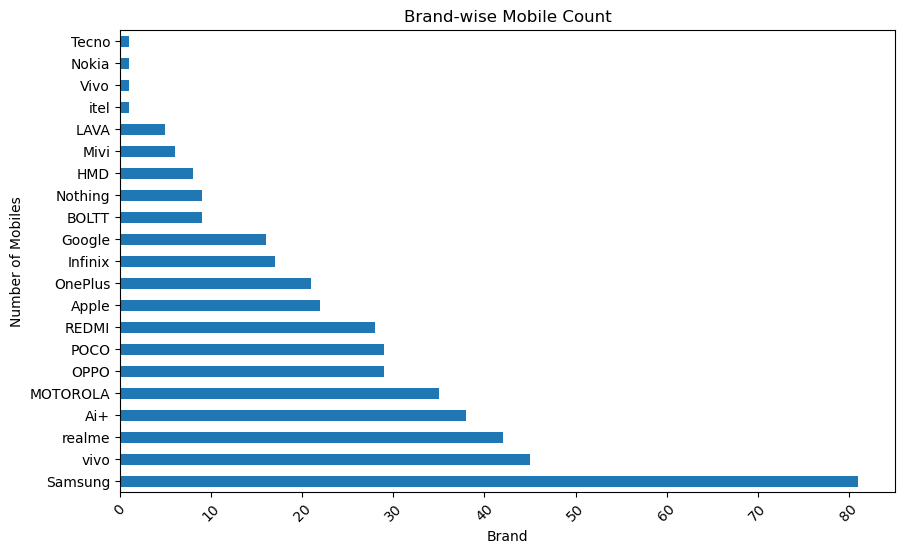

In [47]:
plt.figure(figsize=(10,6))

cleaned_df["Brand"].value_counts().plot(kind="barh")

plt.title("Brand-wise Mobile Count")
plt.xlabel("Brand")
plt.ylabel("Number of Mobiles")
plt.xticks(rotation=45)

plt.show()

#### 2. Price Distribution

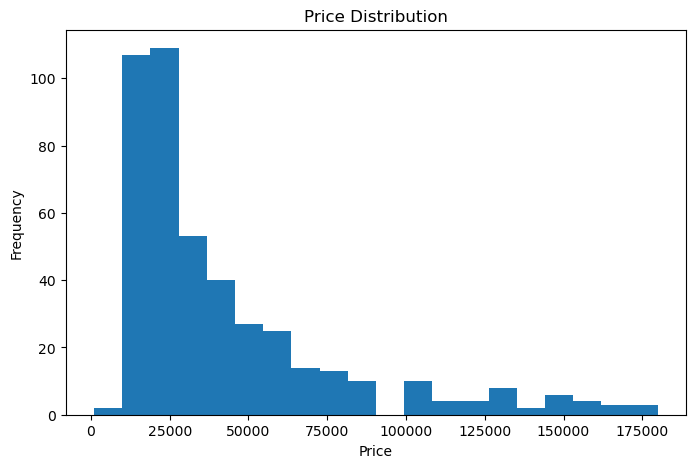

In [40]:
plt.figure(figsize=(8,5))

plt.hist(cleaned_df["Price"], bins=20)

plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

#### 3. RAM Distribution

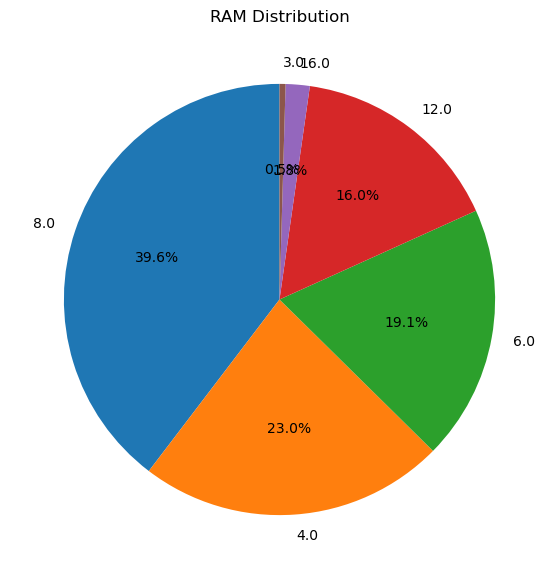

In [48]:
ram = cleaned_df["RAM"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    ram,
    labels=ram.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("RAM Distribution")

plt.show()

#### 4. ROM Distribution

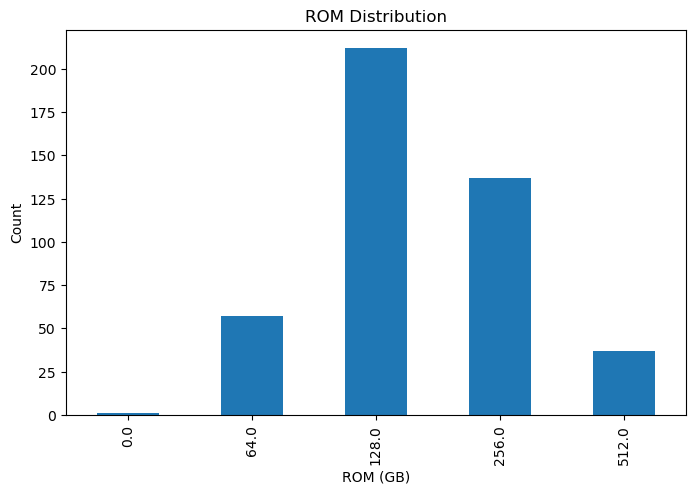

In [42]:
plt.figure(figsize=(8,5))

cleaned_df["ROM"].value_counts().sort_index().plot(kind="bar")

plt.title("ROM Distribution")
plt.xlabel("ROM (GB)")
plt.ylabel("Count")

plt.show()

#### 5. Scatter Plot

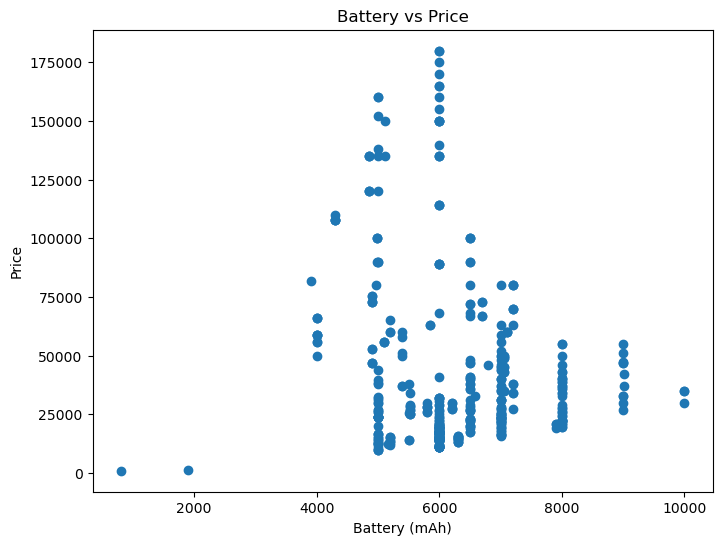

In [49]:
plt.figure(figsize=(8,6))

plt.scatter(cleaned_df["Battery"], cleaned_df["Price"])

plt.title("Battery vs Price")
plt.xlabel("Battery (mAh)")
plt.ylabel("Price")

plt.show()

#### 6. Average Price by Brand

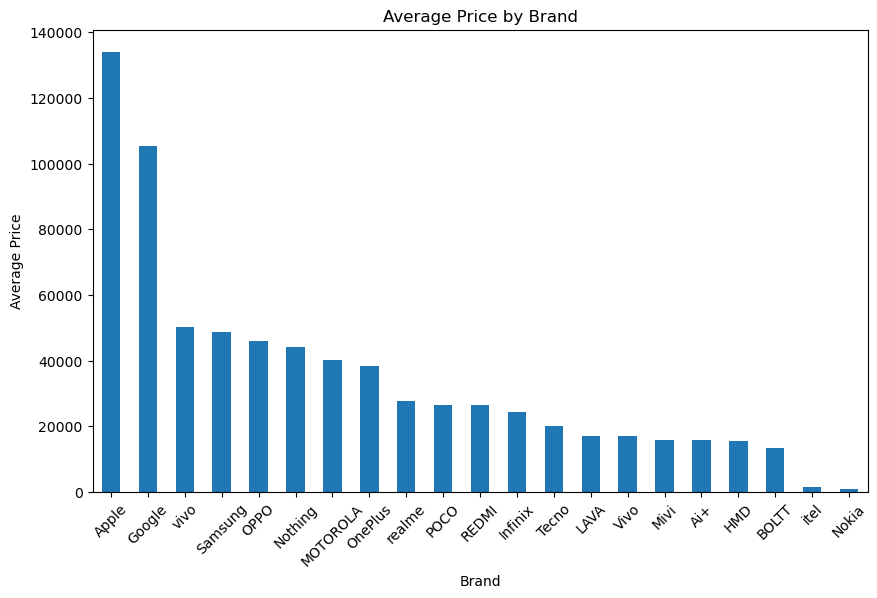

In [44]:
brand_price = cleaned_df.groupby("Brand")["Price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))

brand_price.plot(kind="bar")

plt.title("Average Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")

plt.xticks(rotation=45)

plt.show()

#### 7. Top 10 Expensive Mobiles

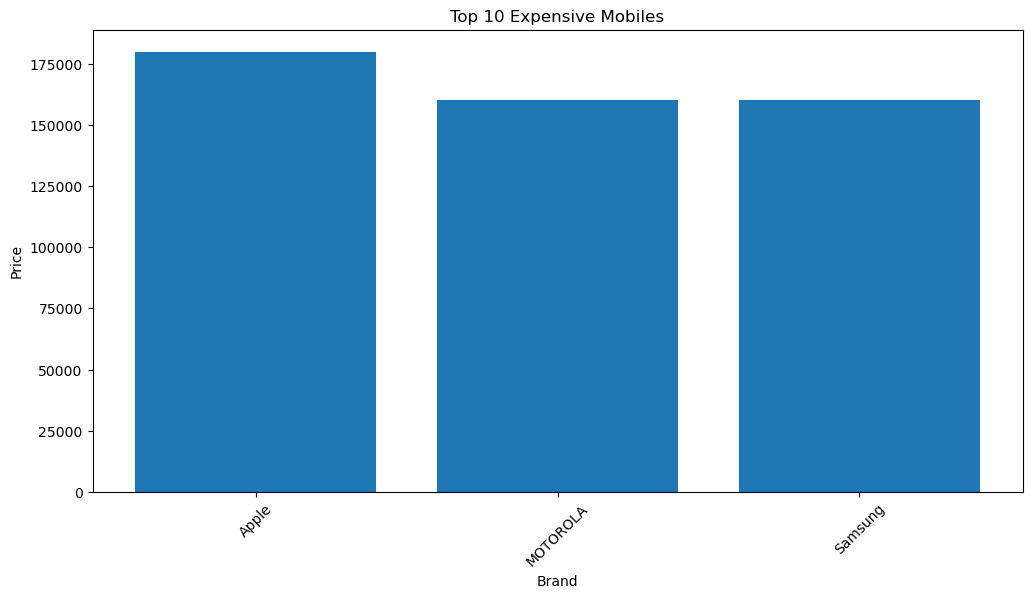

In [45]:
top10 = cleaned_df.nlargest(10, "Price")

plt.figure(figsize=(12,6))

plt.bar(top10["Brand"], top10["Price"])

plt.title("Top 10 Expensive Mobiles")
plt.xlabel("Brand")
plt.ylabel("Price")

plt.xticks(rotation=45)

plt.show()

#### 8. Correlation Heatmap

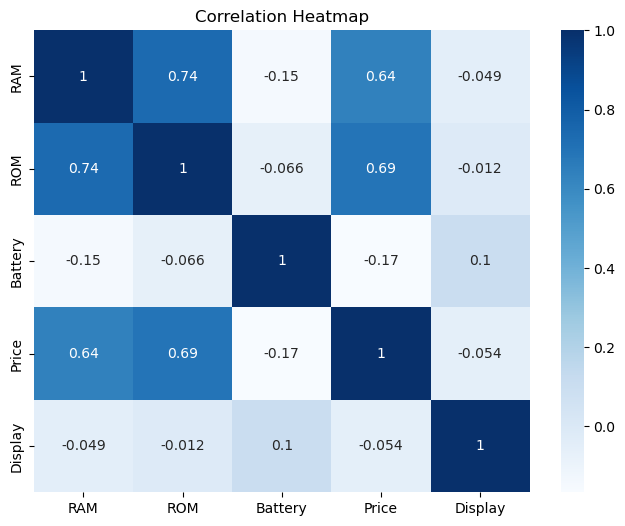

In [46]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cleaned_df.corr(numeric_only=True),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Heatmap")

plt.show()

#### 9. Brand vs Average RAM

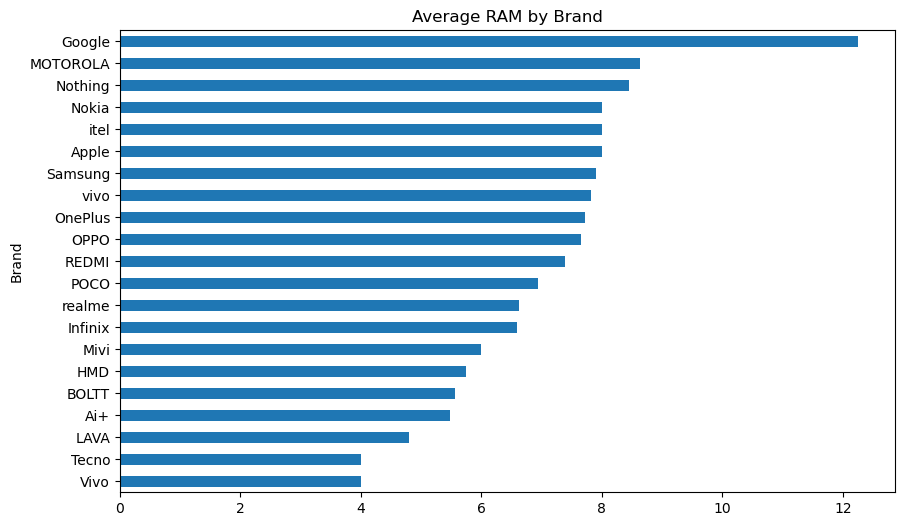

In [51]:
brand_ram = cleaned_df.groupby("Brand")["RAM"].mean().sort_values()

plt.figure(figsize=(10,6))

brand_ram.plot(kind="barh")

plt.title("Average RAM by Brand")

plt.show()

#### 10. Battery Distribution

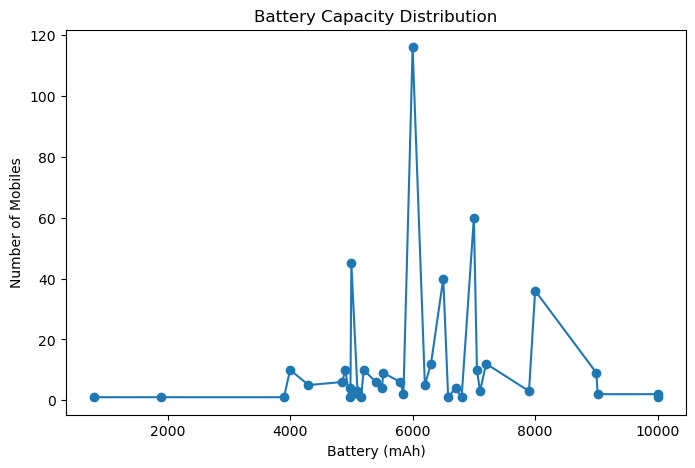

In [52]:
battery = cleaned_df["Battery"].value_counts().sort_index()

plt.figure(figsize=(8,5))

battery.plot(kind="line", marker="o")

plt.title("Battery Capacity Distribution")

plt.xlabel("Battery (mAh)")
plt.ylabel("Number of Mobiles")

plt.show()

## Outlier Analysis

#### 1. Price Outliers

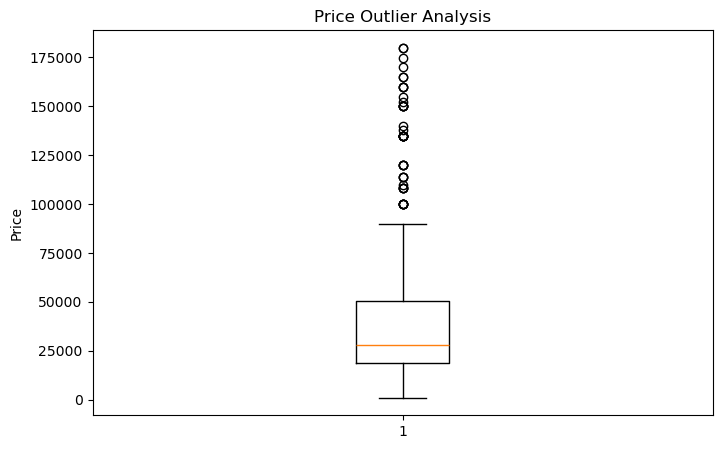

In [54]:
plt.figure(figsize=(8,5))

plt.boxplot(cleaned_df["Price"])

plt.title("Price Outlier Analysis")

plt.ylabel("Price")

plt.show()

#### 2. RAM Outliers

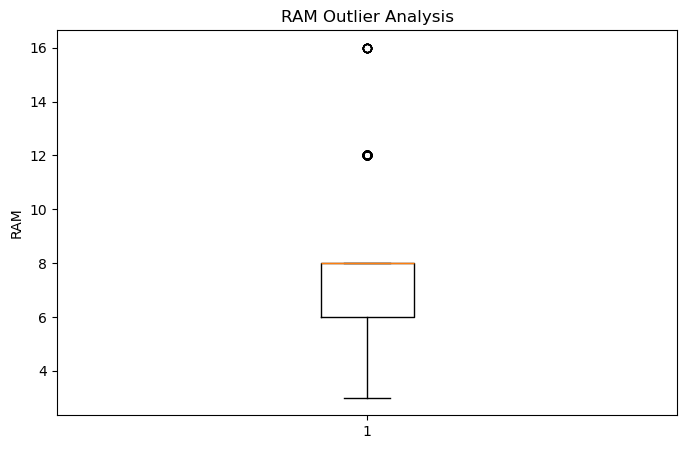

In [55]:
plt.figure(figsize=(8,5))

plt.boxplot(cleaned_df["RAM"])

plt.title("RAM Outlier Analysis")

plt.ylabel("RAM")

plt.show()

#### 3. Battery Outliers

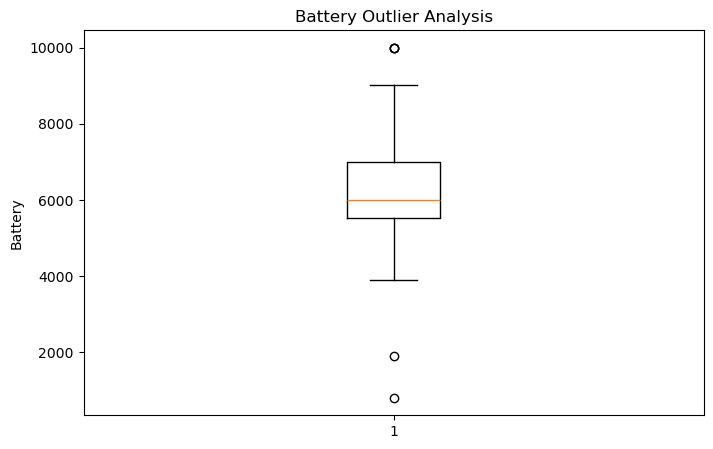

In [56]:
plt.figure(figsize=(8,5))

plt.boxplot(cleaned_df["Battery"])

plt.title("Battery Outlier Analysis")

plt.ylabel("Battery")

plt.show()

##### Observation:

- A few premium mobile phones have significantly higher prices than the majority.
- RAM values show very few outliers.
- Battery capacities are mostly concentrated around common values such as 5000 mAh.
- These outliers represent genuine premium devices rather than data errors, so they are retained.

## Feature Engineering

In [57]:
# Price Category

cleaned_df["Price Category"] = pd.cut(
    cleaned_df["Price"],
    bins=[0,15000,30000,60000,1000000],
    labels=["Budget","Mid Range","Premium","Flagship"]
)

cleaned_df.head()

,Brand,Model,RAM,ROM,Battery,Price,Display,Color,Price Category
0,BOLTT,BOLTT ACE 5G,4.0,64.0,6000.0,11999,17.25,Sky Blue,Budget
1,BOLTT,BOLTT EVO,4.0,64.0,6000.0,10999,17.25,Midnight Black,Budget
2,Apple,Apple iPhone 17,8.0,256.0,6000.0,88999,16.00,Lavender,Flagship
3,LAVA,LAVA Virat V1 5G,4.0,64.0,6000.0,13499,17.14,Arya Blue,Budget
4,OPPO,OPPO K14 Plus 5G,6.0,128.0,8000.0,32999,17.22,Star White,Premium


In [61]:
# RAM Category

cleaned_df["RAM Category"] = pd.cut(
    cleaned_df["RAM"],
    bins=[0,4,8,12,20],
    labels=["Low","Medium","High","Ultra"]
)

cleaned_df["RAM Category"].head(10)

0       Low
1       Low
2    Medium
3       Low
4    Medium
5    Medium
6    Medium
7       Low
8    Medium
9    Medium
Name: RAM Category, dtype: category
Categories (4, object): ['Low' < 'Medium' < 'High' < 'Ultra']

In [63]:
# Battery Category

cleaned_df["Battery Category"] = pd.cut(
    cleaned_df["Battery"],
    bins=[0,4000,5000,6000,8000],
    labels=["Low","Average","High","Very High"]
)
cleaned_df["Battery Category"].head(10)

0         High
1         High
2         High
3         High
4    Very High
5          NaN
6         High
7    Very High
8         High
9         High
Name: Battery Category, dtype: category
Categories (4, object): ['Low' < 'Average' < 'High' < 'Very High']

In [64]:
cleaned_df.head()

,Brand,Model,RAM,ROM,Battery,Price,Display,Color,Price Category,RAM Category,Battery Category
0,BOLTT,BOLTT ACE 5G,4.0,64.0,6000.0,11999,17.25,Sky Blue,Budget,Low,High
1,BOLTT,BOLTT EVO,4.0,64.0,6000.0,10999,17.25,Midnight Black,Budget,Low,High
2,Apple,Apple iPhone 17,8.0,256.0,6000.0,88999,16.00,Lavender,Flagship,Medium,High
3,LAVA,LAVA Virat V1 5G,4.0,64.0,6000.0,13499,17.14,Arya Blue,Budget,Low,High
4,OPPO,OPPO K14 Plus 5G,6.0,128.0,8000.0,32999,17.22,Star White,Premium,Medium,Very High


## Additional Analysis

In [65]:
# Mobile Count by Price Category

cleaned_df["Price Category"].value_counts()

Price Category
Mid Range    177
Premium      121
Flagship      85
Budget        61
Name: count, dtype: int64

In [66]:
# Average Price by Brand

cleaned_df.groupby("Brand")["Price"].mean().sort_values(ascending=False)

Brand
Apple       134072.363636
Google      105499.000000
vivo         50222.333333
Samsung      48554.382716
OPPO         46067.965517
Nothing      44221.222222
MOTOROLA     40249.000000
OnePlus      38247.714286
realme       27635.142857
POCO         26430.034483
REDMI        26301.035714
Infinix      24234.294118
Tecno        19999.000000
LAVA         17099.000000
Vivo         16999.000000
Mivi         15915.666667
Ai+          15683.210526
HMD          15624.000000
BOLTT        13387.888889
itel          1495.000000
Nokia          999.000000
Name: Price, dtype: float64

In [67]:
# Average Battery by Brand

cleaned_df.groupby("Brand")["Battery"].mean().sort_values(ascending=False)

Brand
OnePlus     7690.476190
realme      7330.976190
OPPO        7096.551724
POCO        7015.862069
vivo        6909.777778
MOTOROLA    6622.857143
Tecno       6500.000000
Infinix     6182.352941
REDMI       6002.142857
BOLTT       6000.000000
HMD         6000.000000
Vivo        6000.000000
Mivi        6000.000000
Apple       6000.000000
Ai+         5947.368421
LAVA        5800.000000
Nothing     5600.000000
Samsung     5017.283951
Google      4971.250000
itel        1900.000000
Nokia        800.000000
Name: Battery, dtype: float64

In [68]:
# Average RAM by Brand

cleaned_df.groupby("Brand")["RAM"].mean().sort_values(ascending=False)

Brand
Google      12.250000
MOTOROLA     8.628571
Nothing      8.444444
itel         8.000000
Apple        8.000000
Nokia        8.000000
Samsung      7.901235
vivo         7.822222
OnePlus      7.714286
OPPO         7.655172
REDMI        7.392857
POCO         6.931034
realme       6.619048
Infinix      6.588235
Mivi         6.000000
HMD          5.750000
BOLTT        5.555556
Ai+          5.473684
LAVA         4.800000
Tecno        4.000000
Vivo         4.000000
Name: RAM, dtype: float64

## 📌 Business Insights

#### Executive Summary

         This project analyzed mobile phone listings collected from Flipkart using web scraping techniques. The dataset contains product specifications such as brand, model, price, RAM, ROM, display size, battery capacity, camera details, and processor information. After cleaning and analyzing the dataset, several market trends and product characteristics were identified.

#### 1. Brand Market Presence

The analysis indicates that a few leading brands account for the majority of mobile phone listings on Flipkart. This suggests a highly competitive market where established brands dominate product availability and customer visibility.

#### 2. Pricing Trends

The smartphone market is primarily concentrated in the budget and mid-range segments, while premium and flagship devices represent a smaller proportion of the available products. This reflects the strong demand for affordable smartphones.

#### 3. Hardware Configuration

Most smartphones are equipped with 8 GB RAM and 128 GB ROM, showing that manufacturers are focusing on configurations that balance performance and affordability.

#### 4. Battery Capacity

A 5000 mAh battery is the most common specification across the dataset, indicating that long battery life has become a standard feature in modern smartphones.

#### 5. Processor Analysis

The analysis shows that Snapdragon and MediaTek processors are widely used across different price categories, highlighting their popularity in the Android smartphone ecosystem.

#### 6. Premium Segment

Premium smartphones are fewer in number but command significantly higher prices. These devices generally include advanced processors, higher storage capacities, and flagship-level features.

#### 7. Product Diversity

The availability of multiple RAM, ROM, battery, and processor combinations provides customers with a wide range of choices based on their budget and performance requirements.

#### 8. Consumer Preferences

The distribution of specifications suggests that customers prefer smartphones offering high battery capacity, sufficient RAM, and balanced pricing over extremely high-end configurations.

## 📌 Business Recommendations

### Recommendations

#### Product Strategy

- Maintain a larger inventory of smartphones from the most frequently listed brands.
- Focus promotional campaigns on devices with the most popular hardware configurations.
- Continuously monitor market pricing to remain competitive.
  
### Customer Experience

- Introduce product recommendation systems based on customer budgets and preferred specifications.
- Improve product comparison features to help users evaluate similar smartphones.
  
### Marketing Strategy

- Promote smartphones with strong value-for-money specifications.
- Highlight devices offering better battery life and higher RAM capacity.
- Create category-based promotions for budget, mid-range, and premium smartphones.

### Inventory Management

- Track high-demand configurations and ensure consistent stock availability.
- Monitor newly launched devices to update product listings regularly.

## 📌 Conclusion

This project demonstrates the complete data analytics workflow, starting from web scraping and ending with business insights. Mobile phone data was successfully collected from Flipkart using Python and transformed into a structured dataset for analysis.

The project involved data extraction, preprocessing, exploratory data analysis, and visualization to identify trends in pricing, hardware specifications, and brand distribution. These analyses provide valuable insights into the online smartphone marketplace and can support inventory planning, pricing strategies, and customer decision-making.

This project also demonstrates practical skills in:
- Python Programming
- Web Scraping (Requests & BeautifulSoup)
- Data Cleaning
- Data Transformation
- Exploratory Data Analysis (EDA)
- Data Visualization
- Business Insight Generation

This project successfully collected mobile phone data from Flipkart using web scraping techniques. The scraped data was cleaned, analyzed, and visualized to understand market trends based on price, RAM, ROM, battery capacity, processor, and brand. The analysis provides useful insights into smartphone specifications and pricing, helping customers and businesses make informed decisions.

## Export the Final Dataset

In [71]:
cleaned_df.to_csv("Flipkart_Mobile_Cleaned.csv", index=False)

print("Project Completed Successfully!")

Project Completed Successfully!
